# Two ways to estimate crowding: direct counting vs station graph + ML

**Question.** How many riders are on board each stretch of each route, by hour? Two approaches are built here and tested on the same held-out week.

| | **A · Direct counting** | **B · Station graph + ML** |
|---|---|---|
| Idea | Each ticket says *boarded at i, getting off at j*. Count the rider on every stretch from i to j, average over past days. | Build a graph of all stations. Use ML to predict **how many board** and **how many get off** at every station and hour, rebuild who-rides-where with a gravity model, then run the count along the route. |
| Uses | The tickets on that route | Station graph features + demand at the same station on other routes + (if available) the route's own history |
| Output | Riders on board per stretch, per hour | Boardings and alightings per stop, the origin–destination table, riders on board per stretch, per hour |

**Test setup.** Learn from the weekdays of 5–23 October (14 days, holidays excluded). Predict the weekdays of **26–30 October**, which neither
approach has seen. Compare against what the tickets of that week actually show. Two tests:
1. **Known routes**: routes that have past tickets (all 1,091 ordered route-directions).
2. **Unseen routes**: a quarter of all routes (both directions) are hidden from B entirely, as if they were new, and B must predict them from the graph alone.

All numbers are **e-ticket riders per day**. Scaling to all riders and dividing by buses per hour is the same for both approaches, so it is left out of the comparison.

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from crowding.data import load_tickets, window, stop_activity, loads_from_activity
from crowding.stops import infer_route_orders, stop_display_names, attach_positions
from crowding.graph import build_station_graph, stop_graph_features, graph_summary
from crowding import approach_a, approach_b as B
from crowding.evaluate import score_table

OUT = ROOT / 'outputs'; OUT.mkdir(exist_ok=True)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
BLUE, ORANGE, AQUA, GREY, INK = '#2a78d6', '#eb6834', '#1baf7a', '#9a9993', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c9c8c2',
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.titlesize': 11, 'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'font.size': 9, 'legend.frameon': False, 'lines.linewidth': 2,
})
t0 = time.time()
log = lambda m: print(f'[{time.time() - t0:5.1f}s] {m}')

## 1 · Shared preparation

Both approaches need the **order of stops** on each route. Until the GTFS feed arrives, it is recovered from the tickets themselves
(every ticket votes "boarding stop comes before alighting stop"). Stop names are normalised so spacing and punctuation variants merge.

In [2]:
df = load_tickets()
route_stops = infer_route_orders(df, use_time=False)   # vote-based order, as used for this comparison
names = stop_display_names(df)
tp = attach_positions(df, route_stops)            # tickets with stop positions, boarding before alighting
route_ac = df.groupby('route')['is_ac'].mean()
r = route_stops.groupby('route').first()
print(f"{len(r):,} route-directions ordered ({r.route_base.nunique():,} routes) | stops per route: median {r.n_stops.median():.0f}")
print(f"order consistency (share of riders whose boarding stop comes before their alighting stop): median {r.order_consistency.median():.1%}, "
      f"5th pct {r.order_consistency.quantile(.05):.1%}")
print(f"tickets usable by both approaches: {tp.passenger_count.sum() / df.passenger_count.sum():.1%} of all passengers")

train_t, n_train = window(tp, [41, 42, 43])        # weekdays 5-23 Oct (holiday 20 Oct excluded)
test_t, n_test = window(tp, [44])                  # weekdays 26-30 Oct
print(f'learn from {n_train} weekdays, test on {n_test} weekdays')
act_test = stop_activity(test_t, route_stops, n_test)
truth = loads_from_activity(act_test).rename(columns={'load': 'truth'})
log('prepared')

1,091 route-directions ordered (592 routes) | stops per route: median 36
order consistency (share of riders whose boarding stop comes before their alighting stop): median 96.2%, 5th pct 86.8%
tickets usable by both approaches: 91.2% of all passengers


learn from 14 weekdays, test on 5 weekdays


[  6.6s] prepared


## 2 · The station graph (used by approach B)

Every normalised stop is a node; two stops are linked if they are consecutive on at least one route. The graph is what lets a model learn
from *other* routes: a station that is busy at 9 am on ten routes is probably busy on the eleventh.

In [3]:
G = build_station_graph(route_stops)
stop_feats = stop_graph_features(G, route_stops, names)
display(graph_summary(G).to_frame('value'))

board_by_stop = tp.groupby('ss_key')['passenger_count'].sum()
top = stop_feats.assign(boardings=stop_feats.stop_key.map(board_by_stop).fillna(0), name=stop_feats.stop_key.map(names))
display(top.sort_values('pagerank', ascending=False)[['name', 'n_routes', 'in_deg', 'out_deg', 'pagerank', 'betweenness', 'boardings']].head(10)
        .rename(columns={'n_routes': 'routes', 'in_deg': 'links in', 'out_deg': 'links out'}).reset_index(drop=True))

,value
stations (nodes),4951
links between consecutive stops (edges),32724
connected pieces,1
stations in largest piece,4951
share in largest piece,100.0%
median neighbours per station,6.000
stations with 6+ neighbours (interchanges),2757


,name,routes,links in,links out,pagerank,betweenness,boardings
0,Shivaji Park,69,91,88,10.864,0.033,"3,472.000"
1,Dhaula Kuan,61,75,70,8.892,0.024,"11,069.000"
2,Gtk Depot,51,64,52,8.482,0.009,"6,654.000"
3,East Patel Nagar,53,67,74,8.388,0.015,"3,984.000"
4,Telephone Exchange,43,69,65,8.356,0.024,"6,166.000"
5,Andrews Ganj,47,52,53,8.221,0.008,"10,822.000"
6,Super Bazar,68,62,56,8.197,0.019,"6,575.000"
7,Desu Colony Janakpuri,47,58,58,8.024,0.010,"5,987.000"
8,Isbt Nityanand Marg,63,56,66,7.717,0.014,"7,871.000"
9,Rainy Well,42,66,65,7.623,0.016,"5,147.000"


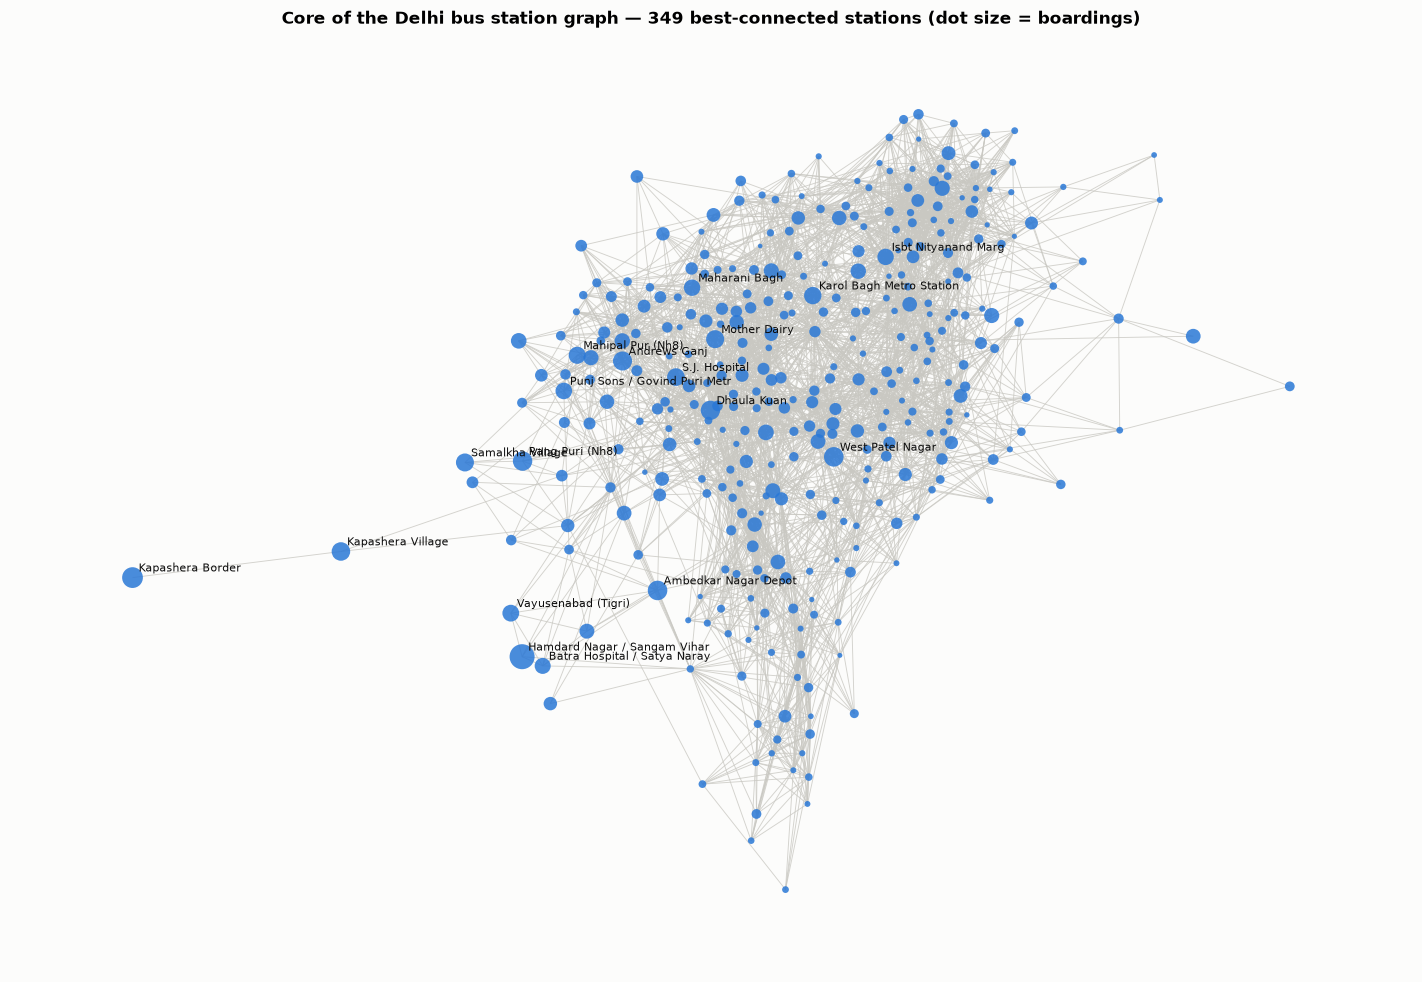

In [4]:
# Picture of the network's core: the 350 most-connected stations. Layout is abstract (no coordinates until GTFS).
core_nodes = top.nlargest(350, 'n_routes').stop_key.tolist()
H = G.subgraph(core_nodes).to_undirected()
H = H.subgraph(max(nx.connected_components(H), key=len))
pos = nx.spring_layout(H, k=0.35, iterations=200, seed=3, weight=None)
bsize = top.set_index('stop_key').boardings
fig, ax = plt.subplots(figsize=(13, 9))
nx.draw_networkx_edges(H, pos, ax=ax, edge_color='#c9c8c2', width=0.6, alpha=0.8)
sizes = np.array([bsize.get(n, 0) for n in H.nodes])
nx.draw_networkx_nodes(H, pos, ax=ax, node_size=8 + 260 * sizes / sizes.max(), node_color=BLUE, alpha=0.85, linewidths=0)
lab = sorted(H.nodes, key=lambda n: -bsize.get(n, 0))[:18]
for n in lab:
    ax.annotate(names.get(n, n)[:28], pos[n], xytext=(4, 4), textcoords='offset points', fontsize=7.5, color='#0b0b0b')
ax.set_title(f'Core of the Delhi bus station graph — {H.number_of_nodes()} best-connected stations (dot size = boardings)')
ax.axis('off'); plt.tight_layout(); plt.show()

## 3 · Approach A — direct counting

In [5]:
A = approach_a.estimate(train_t, route_stops, n_train)
log(f'approach A: {len(A):,} stretch-hour estimates')
A.head()

[ 13.8s] approach A: 704,286 stretch-hour estimates


,route,route_base,pos,hour,n_stops,load_A,n_tix_A
0,03DOWN,03,0,5,26,0.000,0.000
1,03DOWN,03,1,5,26,0.000,0.000
2,03DOWN,03,2,5,26,0.000,0.000
3,03DOWN,03,3,5,26,0.000,0.000
4,03DOWN,03,4,5,26,0.000,0.000


## 4 · Approach B — station graph + ML + origin–destination rebuild

**Features per (route, stop, hour)**
- *Position:* stop number, share of the way along the route, stops to the end, route length, hour, AC share of the route.
- *Graph:* links in/out, routes served, PageRank, betweenness, place type from the name (metro, ISBT, terminal, border, village, hospital, market, junction, education, airport).
- *Network demand:* boardings/alightings at the same station on **other** routes (whole route, both directions, left out), overall and at that hour.
- *Route history (known routes only):* this stop's and this route's own past boardings/alightings.

**Models.** Two LightGBM regressors with Poisson loss: one for boardings, one for alightings.
Training rows come from **cross-fitting over days**: the 14 learning days are split into 3 folds; features come from two folds and targets
from the third, rotating. So the model learns how past averages relate to a new day without any single odd week biasing it.

**Origin–destination rebuild.** Predicted boardings and alightings are two separate columns; they don't say who goes where. A
gravity model seeded with the observed trip-length distribution, balanced with iterative proportional fitting (IPF), builds the
from-i-to-j table (only downstream stops allowed). The running count then gives riders on board.

In [6]:
prior = B.trip_length_prior(train_t, int(route_stops.n_stops.max()))

# Sanity check: fed the TRUE boardings and alightings of the test week, does the rebuild reproduce the true loads?
chk = B.rebuild_loads(act_test.rename(columns={'board': 'board_pred', 'alight': 'alight_pred'}), prior)
m = truth.merge(chk, on=['route', 'pos', 'hour'])
print(f"OD rebuild from true boardings/alightings: error {np.abs(m.load_B - m.truth).sum() / m.truth.sum():.2%} -> the rebuild step loses nothing")

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    cf_train = B.crossfit_training_set(train_t, route_stops, stop_feats, route_ac)
    log(f'cross-fit training rows: {len(cf_train):,}')
    models_warm = B.fit_crossfit(cf_train, B.FEATURES_WARM)
    X_pred = B.build_features(train_t, n_train, route_stops, stop_feats, route_ac)
    act_B = B.predict_activity(models_warm, X_pred)
    LB = B.rebuild_loads(act_B, prior)
log('approach B trained and applied')

OD rebuild from true boardings/alightings: error 0.05% -> the rebuild step loses nothing


[ 23.4s] cross-fit training rows: 2,171,772


[121.8s] approach B trained and applied


## 5 · Result 1 — known routes, held-out week

Scores are over every (route-direction, stretch, hour) cell in the test week.

- **WMAPE**: total absolute error ÷ total riders (lower is better).
- **bias**: over- or under-estimate overall.
- **busiest-10 % found**: share of the true busiest 10 % of stretch-hours that the method also puts in its top 10 %. This matters most for a crowding warning.
- **level agreement**: same crowding level (seats / standing / crowded), cut at the 60th and 90th network percentiles.

In [7]:
ev = truth.merge(A, on=['route', 'route_base', 'pos', 'hour', 'n_stops']).merge(LB, on=['route', 'pos', 'hour'])
levels = tuple(np.quantile(ev.load_A, [0.6, 0.9]))
vol = A.groupby('route').load_A.sum()
ev['route tier'] = pd.qcut(ev.route.map(vol), 3, labels=['thin routes', 'medium routes', 'busy routes'])
methods = {'A · direct counting': 'load_A', 'B · graph + ML': 'load_B'}
res_known = score_table(ev, 'truth', methods, levels)
res_tier = score_table(ev, 'truth', methods, levels, by='route tier')

# Rough noise floor: error a perfect estimate would still show, from Poisson randomness alone over 5 test days
rng = np.random.default_rng(0); mu = ev.load_A.clip(lower=1e-6).to_numpy()
floor = np.mean([np.abs(rng.poisson(mu * n_test) / n_test - mu).sum() / mu.sum() for _ in range(20)])
print(f'{len(ev):,} stretch-hour cells | noise floor (Poisson only, a lower bound): WMAPE ≈ {floor:.2f}')
res_known

704,286 stretch-hour cells | noise floor (Poisson only, a lower bound): WMAPE ≈ 0.18


,WMAPE,bias,MAE (riders/day),Pearson r,Spearman ρ,busiest-10% found,level agreement
A · direct counting,0.298,0.001,0.612,0.960,0.896,0.838,0.853
B · graph + ML,0.308,-0.003,0.632,0.956,0.897,0.835,0.852


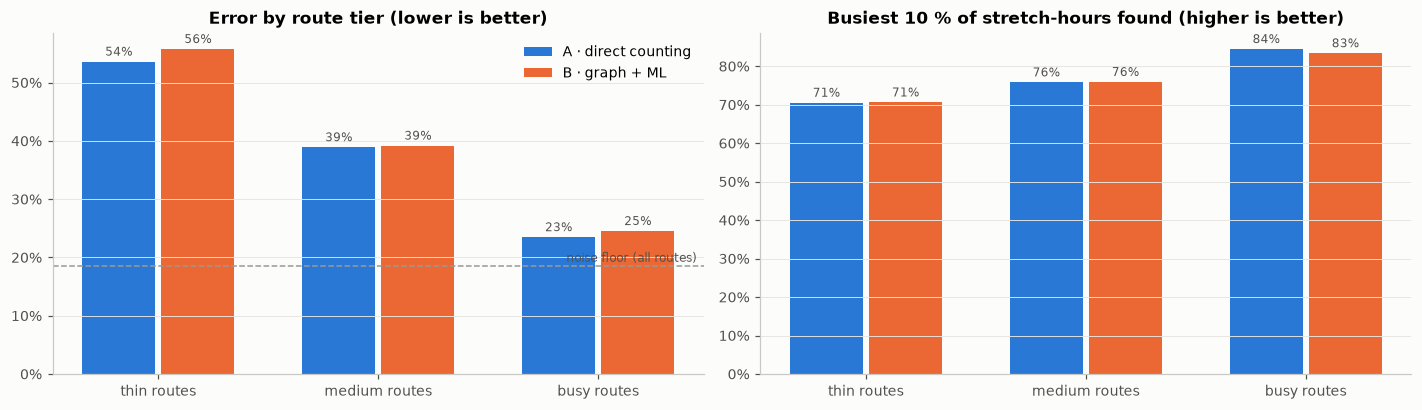

WMAPE   bias  MAE (riders/day)  Pearson r  Spearman ρ  busiest-10% found  level agreement
route tier    method                                                                                                        
thin routes   A · direct counting  0.536 -0.006             0.299      0.856       0.764              0.705            0.905
              B · graph + ML       0.558  0.012             0.311      0.849       0.764              0.706            0.907
medium routes A · direct counting  0.389 -0.007             0.559      0.906       0.851              0.758            0.828
              B · graph + ML       0.392 -0.012             0.563      0.906       0.856              0.759            0.827
busy routes   A · direct counting  0.235  0.005             0.980      0.962       0.937              0.845            0.825
              B · graph + ML       0.245 -0.002             1.024      0.957       0.935              0.834            0.822

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
tiers = ['thin routes', 'medium routes', 'busy routes']
x = np.arange(len(tiers)); w = 0.36
for ax, metric, title in [(axes[0], 'WMAPE', 'Error by route tier (lower is better)'),
                          (axes[1], 'busiest-10% found', 'Busiest 10 % of stretch-hours found (higher is better)')]:
    for k, (name, c) in enumerate(zip(methods, [BLUE, ORANGE])):
        vals = res_tier[res_tier.method == name].set_index('route tier').loc[tiers, metric]
        bars = ax.bar(x + (k - 0.5) * w, vals, w * 0.92, color=c, label=name)
        ax.bar_label(bars, fmt='{:.0%}', fontsize=8, color=INK, padding=2)
    ax.set_xticks(x); ax.set_xticklabels(tiers); ax.set_title(title); ax.grid(axis='x', visible=False)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
if floor: axes[0].axhline(floor, color=GREY, lw=1, ls='--'); axes[0].annotate('noise floor (all routes)', (2.45, floor), xytext=(0, 3), textcoords='offset points', ha='right', fontsize=8, color=INK)
axes[0].legend(loc='upper right'); plt.tight_layout(); plt.show()
res_tier.set_index(['route tier', 'method']).drop(columns='cells')

### What it looks like on one route

The busiest route in both directions, weekday 08:00–09:59. Top: riders on board along the route.
Bottom: the stop-by-stop **boardings (up) and alightings (down)** that approach B predicts, against what the test week showed.

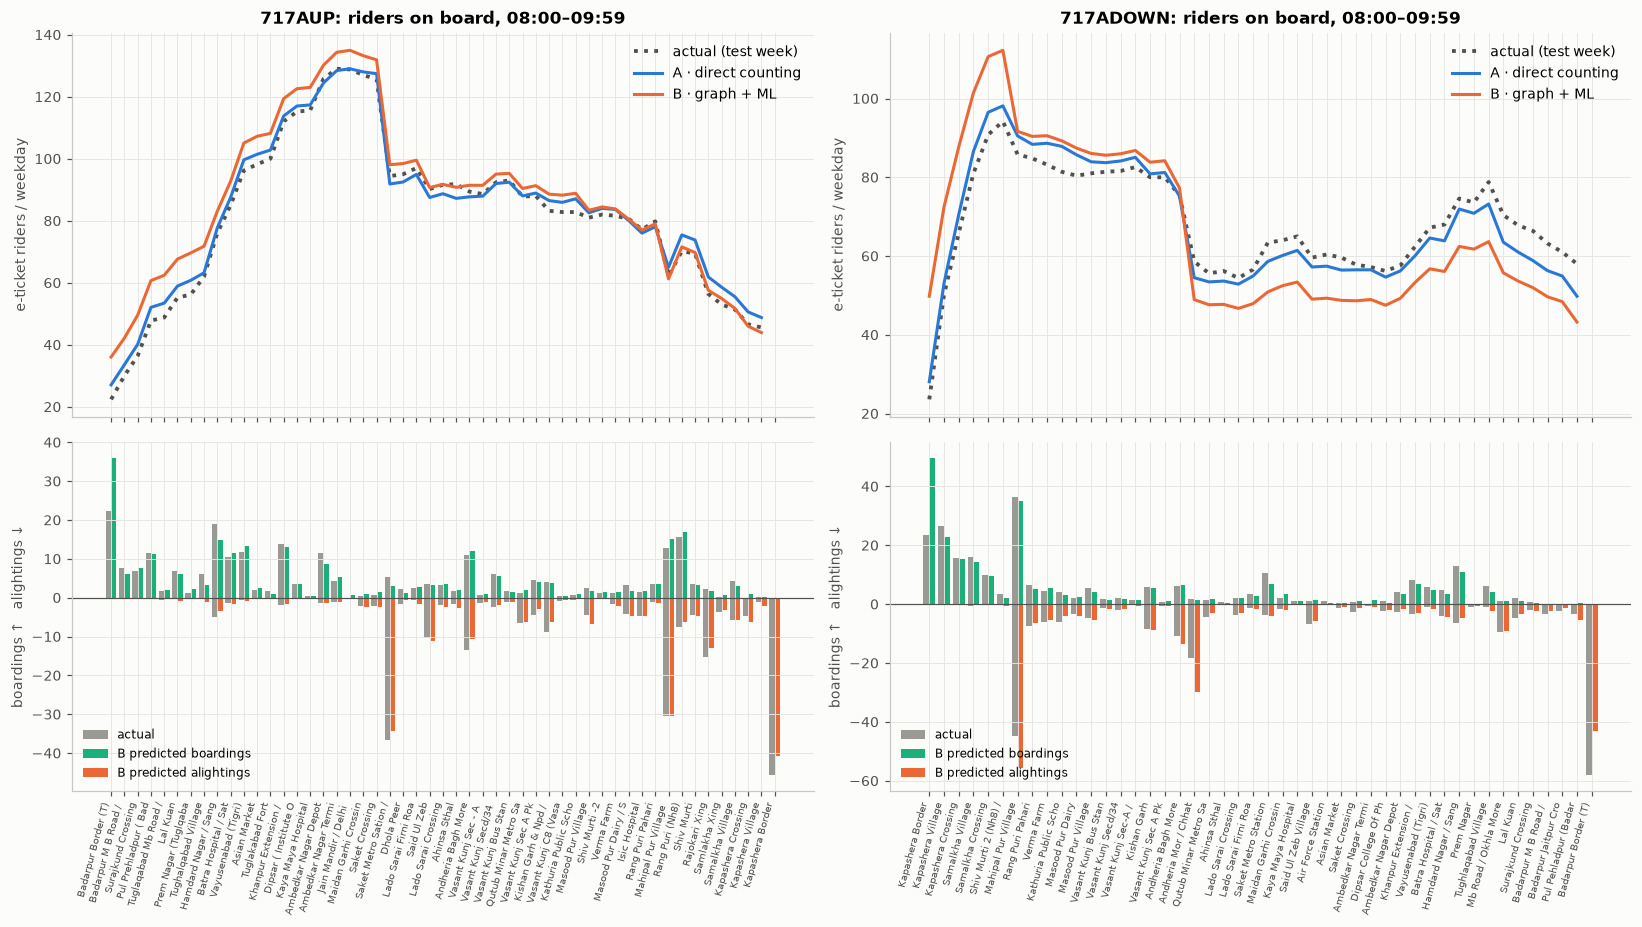

In [9]:
def profile(route, hours, frame, col):
    s = frame[(frame.route == route) & frame.hour.isin(hours)].groupby('pos')[col].sum()
    return s.reindex(range(int(route_stops[route_stops.route == route].n_stops.iat[0]))).fillna(0)

DEMO = df.route_base.value_counts().index[0]
HRS = [8, 9]
fig, axes = plt.subplots(2, 2, figsize=(15, 8.5), sharex='col', gridspec_kw={'height_ratios': [1.1, 1]})
for c, d in enumerate(['UP', 'DOWN']):
    rt = f'{DEMO}{d}'
    stops = route_stops[route_stops.route == rt].sort_values('pos').stop_key.map(names).str[:20].tolist()
    ax = axes[0, c]
    for col, frame, color, lab in [('truth', ev, INK, 'actual (test week)'), ('load_A', ev, BLUE, 'A · direct counting'),
                                   ('load_B', ev, ORANGE, 'B · graph + ML')]:
        p = profile(rt, HRS, frame, col)
        ax.plot(p.index[:-1], p.values[:-1], color=color, label=lab, lw=2 if col != 'truth' else 2.5,
                ls='-' if col != 'truth' else ':')
    ax.set_title(f'{rt}: riders on board, 08:00–09:59'); ax.set_ylabel('e-ticket riders / weekday'); ax.legend(loc='upper right')
    ax = axes[1, c]
    bt = act_test[(act_test.route == rt) & act_test.hour.isin(HRS)].groupby('pos')[['board', 'alight']].sum()
    bp = act_B[(act_B.route == rt) & act_B.hour.isin(HRS)].groupby('pos')[['board_pred', 'alight_pred']].sum()
    xs = np.arange(len(stops))
    ax.bar(xs - 0.2, bt.board.reindex(xs).fillna(0), 0.4, color=GREY, label='actual')
    ax.bar(xs - 0.2, -bt.alight.reindex(xs).fillna(0), 0.4, color=GREY)
    ax.bar(xs + 0.2, bp.board_pred.reindex(xs).fillna(0), 0.4, color=AQUA, label='B predicted boardings')
    ax.bar(xs + 0.2, -bp.alight_pred.reindex(xs).fillna(0), 0.4, color=ORANGE, label='B predicted alightings')
    ax.axhline(0, color=INK, lw=0.8); ax.set_ylabel('boardings ↑   alightings ↓'); ax.legend(loc='lower left', fontsize=8)
    ax.set_xticks(xs); ax.set_xticklabels(stops, rotation=75, ha='right', fontsize=6.5)
plt.tight_layout(); plt.show()

### What drives model B (known routes)

Share of total split gain per feature, top 12.

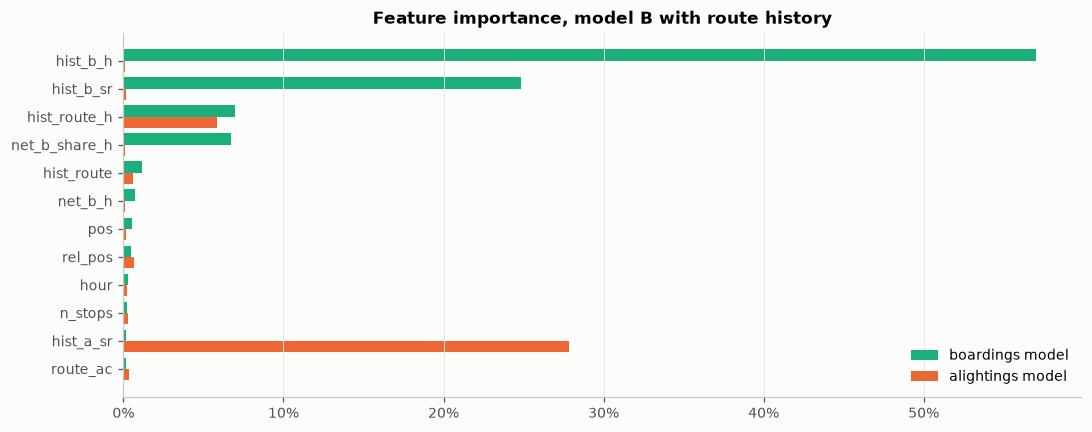

In [10]:
imp_w = B.feature_importance(models_warm)
fig, ax = plt.subplots(figsize=(10, 4))
top12 = imp_w.head(12)[::-1]
y = np.arange(len(top12))
ax.barh(y + 0.2, top12.board, 0.4, color=AQUA, label='boardings model')
ax.barh(y - 0.2, top12.alight, 0.4, color=ORANGE, label='alightings model')
ax.set_yticks(y); ax.set_yticklabels(top12.index); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_title('Feature importance, model B with route history'); ax.legend(loc='lower right'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

## 6 · Result 2 — routes the model has never seen

A quarter of all routes (both directions together) are removed from B's training, and **all their own history is withheld**. B must predict them from
position along the route, the station graph and demand at the same stations on other routes. Compared with:
- a **naive network average**: the average load at that point along a route and hour, over all other routes;
- **A** and **B with history**, as a reference for what having the route's own tickets is worth.

In [11]:
bases = route_stops.route_base.unique()
held = set(np.random.default_rng(42).choice(bases, size=len(bases) // 4, replace=False))
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    models_cold = B.fit_crossfit(cf_train[~cf_train.route_base.isin(held)], B.FEATURES_COLD)
prior_cold = B.trip_length_prior(train_t[~train_t.route_base.isin(held)], int(route_stops.n_stops.max()))
act_cold = B.predict_activity(models_cold, X_pred[X_pred.route_base.isin(held)])
LC = B.rebuild_loads(act_cold, prior_cold).rename(columns={'load_B': 'load_Bcold'})

dec = lambda d: (d.pos / (d.n_stops - 1) * 10).astype(int).clip(upper=9)
naive = A[~A.route_base.isin(held)].assign(dec=dec).groupby(['dec', 'hour']).load_A.mean().rename('naive').reset_index()
evc = ev[ev.route_base.isin(held)].merge(LC, on=['route', 'pos', 'hour']).assign(dec=dec).merge(naive, on=['dec', 'hour'])
print(f'{evc.route.nunique()} held-out route-directions, {len(evc):,} stretch-hour cells')
cold_methods = {'naive network average': 'naive', 'B · graph + ML, no route data': 'load_Bcold',
                'A · direct counting (has route data)': 'load_A', 'B · graph + ML (has route data)': 'load_B'}
res_cold = score_table(evc, 'truth', cold_methods, levels)
log('cold-start test done')
res_cold

273 held-out route-directions, 169,362 stretch-hour cells
[150.6s] cold-start test done


,WMAPE,bias,MAE (riders/day),Pearson r,Spearman ρ,busiest-10% found,level agreement
naive network average,1.051,0.206,1.865,0.415,0.476,0.322,0.507
"B · graph + ML, no route data",0.776,-0.071,1.378,0.619,0.621,0.505,0.668
A · direct counting (has route data),0.321,0.009,0.570,0.952,0.880,0.837,0.858
B · graph + ML (has route data),0.331,0.002,0.588,0.948,0.883,0.834,0.858


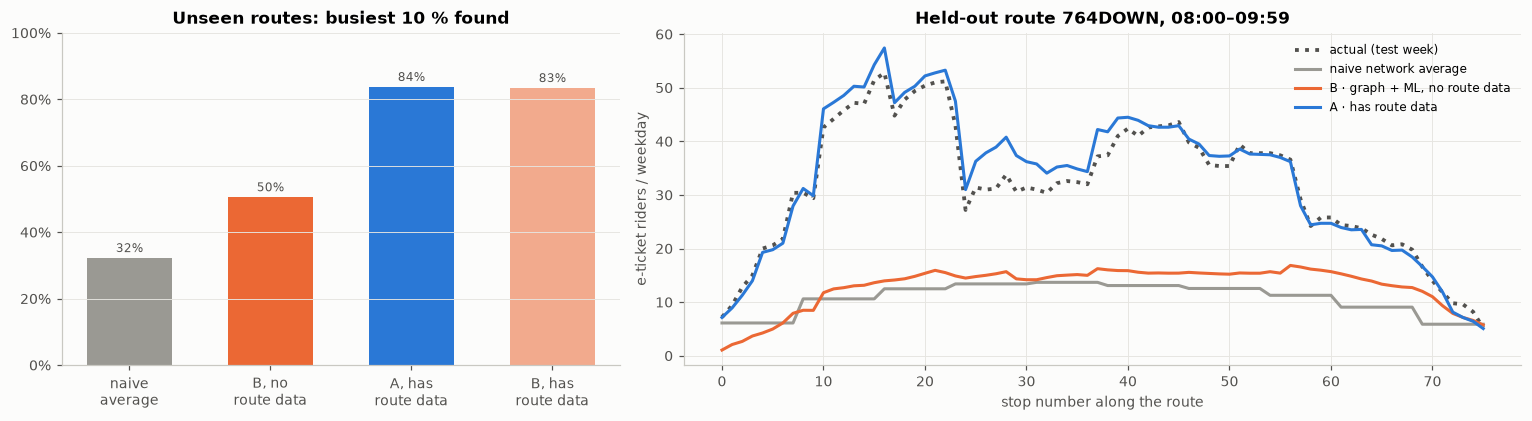

Top features without route history: net_b_h, route_ac, rel_pos, to_end, net_b_share_h, n_stops, in_deg, out_deg


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.9), gridspec_kw={'width_ratios': [1, 1.5]})
ax = axes[0]
labels = ['naive\naverage', 'B, no\nroute data', 'A, has\nroute data', 'B, has\nroute data']
cols = [GREY, ORANGE, BLUE, ORANGE]
vals = res_cold['busiest-10% found'].to_numpy()
bars = ax.bar(labels, vals, color=cols, width=0.6, alpha=1)
bars[3].set_alpha(0.55)
ax.bar_label(bars, fmt='{:.0%}', fontsize=8, color=INK, padding=2)
ax.set_title('Unseen routes: busiest 10 % found'); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.grid(axis='x', visible=False); ax.set_ylim(0, 1)

ax = axes[1]
ex = evc.groupby('route').truth.sum().idxmax()
for col, color, lab, ls in [('truth', INK, 'actual (test week)', ':'), ('naive', GREY, 'naive network average', '-'),
                            ('load_Bcold', ORANGE, 'B · graph + ML, no route data', '-'), ('load_A', BLUE, 'A · has route data', '-')]:
    p = evc[(evc.route == ex) & evc.hour.isin(HRS)].groupby('pos')[col].sum()
    ax.plot(p.index, p.values, color=color, label=lab, ls=ls, lw=2.5 if col == 'truth' else 2)
ax.set_title(f'Held-out route {ex}, 08:00–09:59'); ax.set_xlabel('stop number along the route'); ax.set_ylabel('e-ticket riders / weekday')
ax.legend(loc='upper right', fontsize=8); plt.tight_layout(); plt.show()

imp_c = B.feature_importance(models_cold)
print('Top features without route history:', ', '.join(imp_c.head(8).index))

## 7 · Verdict

| | **A · Direct counting** | **B · Station graph + ML** |
|---|---|---|
| **Accuracy on routes with tickets** | Best: 30 % error (noise floor ≈ 18 %) | About the same (31 %); slightly worse on busy routes. ML can't beat a plain average of a stable pattern |
| **Routes / stops with no tickets** | Nothing to show | **Its real strength**: error 105 % → 78 %, busiest-10 % found 32 % → ~50 % vs a naive average. Still far from having data (A: 32 %) |
| **Uses the "who goes where" in each ticket** | Yes, exactly | No: predicts boardings and alightings separately and rebuilds pairs with a gravity model. Lossless when the counts are right |
| **Explainability for the tech note / judges** | "We counted riders on each stretch": easy to defend, "grounded in the data" | Needs feature, model and IPF explanations; harder to defend as "grounded" |
| **Rerun cost** | Seconds | Minutes (feature building + 2 models + rebuild) |
| **Where it breaks** | Thin routes (noisy, 54 % error); no answer for missing routes/hours | Inherits the same noise; needs more care (training windows, bias) |
| **Extra value** | Ticket counts give a natural confidence flag | Station graph is needed anyway for the journey planner; predicted boardings/alightings per stop are a nice operator view; works with boarding-only data (e.g. ETM) |

**Recommendation.** Use **A as the crowding engine** for every route-hour with enough tickets, with its ticket count as the confidence flag.
Use **B as the fallback** where A has too little data (thin routes, late hours, new routes), and reuse the **station graph** as the planner's backbone.
That combination is a sound model *and* a good story for judges: "counted where we have data, learned from the network where we don't".

In [13]:
ev.to_parquet(OUT / 'eval_known_routes.parquet', index=False)
evc.to_parquet(OUT / 'eval_unseen_routes.parquet', index=False)
pd.concat({'known routes': res_known, 'unseen routes': res_cold}).to_csv(OUT / 'approach_comparison.csv')
route_stops.to_parquet(OUT / 'route_stop_order.parquet', index=False)
stop_feats.assign(name=stop_feats.stop_key.map(names)).to_parquet(OUT / 'station_graph_features.parquet', index=False)
log(f'saved results to {OUT}')

[151.0s] saved results to outputs
